# Assignment 59 — Week 7, Day 3
## Topic: Deep Learning — Loss Functions

**Objective:** Complete the neural-network exercise using the referenced loss-functions guide.

**Reference:** https://www.analyticsvidhya.com/blog/2019/08/detailed-guide-7-loss-functions-machine-learning-python-code/

A **loss function** measures how far a model's predictions are from the true values. Training a neural network means finding the weights that make the loss as small as possible, so the choice of loss function decides *what* the network learns to get right.

- The **loss function** is the error for a single example; the **cost function** is the average loss over the whole data set.
- **Gradient descent** uses the slope (gradient) of the loss to update the weights.

This notebook implements the seven loss functions from the Analytics Vidhya guide in NumPy, checks them against Keras, and then trains neural networks with different losses to compare them.

**Diagram:** Which loss functions suit which kind of problem.

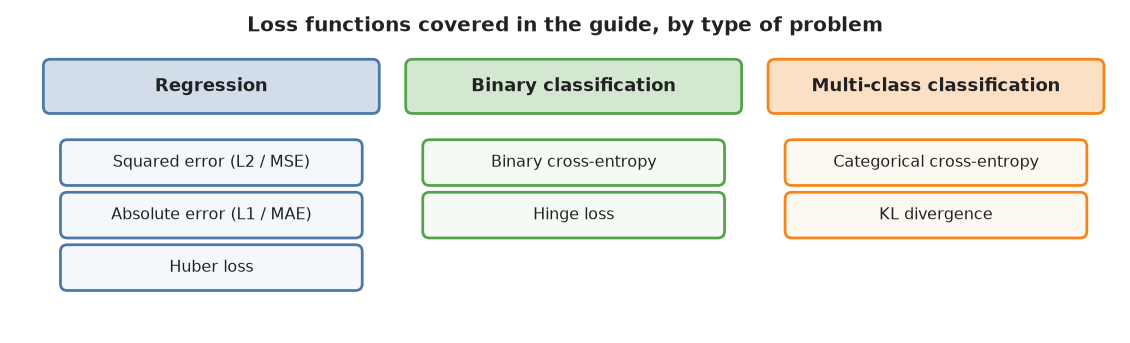

**Set up TensorFlow and Keras**

In [1]:
import os
import logging

# Hide TensorFlow's start-up log messages so the outputs stay readable
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
logging.getLogger("tensorflow").setLevel(logging.ERROR)

import numpy as np
import tensorflow as tf
from tensorflow import keras

tf.get_logger().setLevel(logging.ERROR)
keras.utils.set_random_seed(42)  # makes the results repeatable
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


**Explanation:** The setup cell imports NumPy, TensorFlow and Keras, hides TensorFlow's log messages and fixes the random seed.

## 1. Regression loss functions

**Diagram:** How each regression loss grows as the error gets bigger.

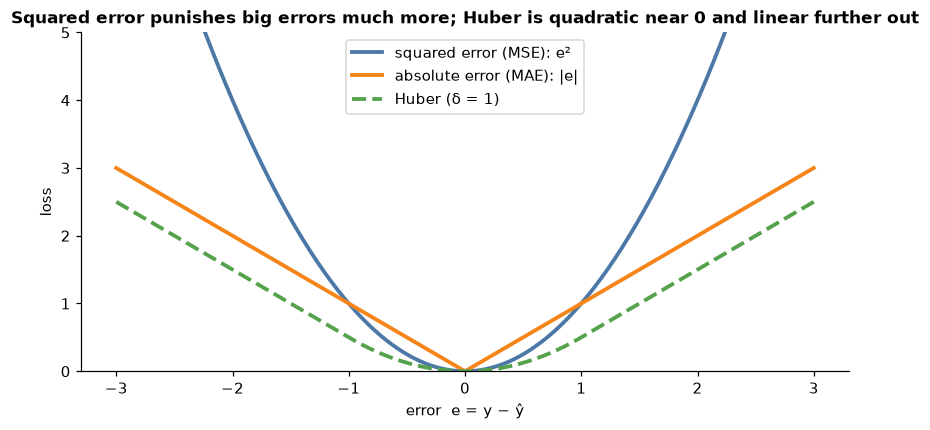

**Squared error (L2) and absolute error (L1)**

In [2]:
import numpy as np

y_true = np.array([3.0, -0.5, 2.0, 7.0])
y_pred = np.array([2.5, 0.0, 2.0, 8.0])

def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

def mae(y, y_hat):
    return np.mean(np.abs(y - y_hat))

print("Mean squared error (L2): ", mse(y_true, y_pred))
print("Mean absolute error (L1):", mae(y_true, y_pred))

Mean squared error (L2):  0.375
Mean absolute error (L1): 0.5


**Explanation:** Squared error squares each difference, so large errors count much more. Absolute error uses the size of each difference, so every unit of error counts equally and outliers have less influence.

**Huber loss**

In [3]:
import numpy as np

y_true = np.array([3.0, -0.5, 2.0, 7.0])
y_pred = np.array([2.5, 0.0, 2.0, 8.0])

def huber(y, y_hat, delta=1.0):
    error = y - y_hat
    small = np.abs(error) <= delta
    return np.mean(np.where(small, 0.5 * error ** 2, delta * (np.abs(error) - 0.5 * delta)))

print("Huber loss (delta=1):", huber(y_true, y_pred))

Huber loss (delta=1): 0.1875


**Explanation:** Huber loss behaves like squared error for small errors (up to delta) and like absolute error for large ones. It combines MSE's smooth gradient near zero with MAE's robustness to outliers.

**Check the NumPy versions against Keras**

In [4]:
import numpy as np
from tensorflow import keras

y_true = np.array([3.0, -0.5, 2.0, 7.0])
y_pred = np.array([2.5, 0.0, 2.0, 8.0])

print("MSE  :", float(keras.losses.MeanSquaredError()(y_true, y_pred)))
print("MAE  :", float(keras.losses.MeanAbsoluteError()(y_true, y_pred)))
print("Huber:", float(keras.losses.Huber(delta=1.0)(y_true, y_pred)))

MSE  : 0.375
MAE  : 0.5
Huber: 0.1875


**Explanation:** Keras has built-in versions of each loss. They give the same values as the NumPy functions above, which confirms the formulas.

**Train a network with MSE vs MAE on data with outliers**

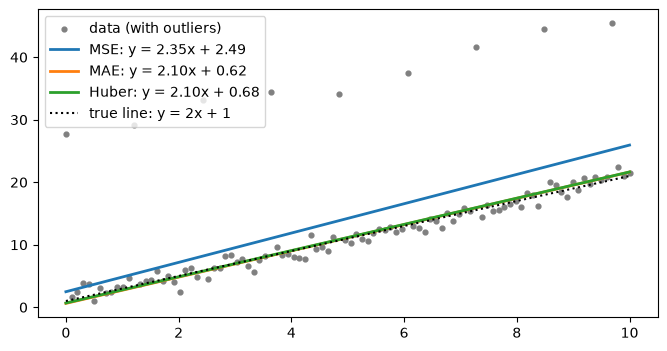

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

keras.utils.set_random_seed(0)
x = np.linspace(0, 10, 100).astype("float32")
y = (2 * x + 1 + np.random.normal(0, 1, 100)).astype("float32")
y[::12] += 25  # add some outliers

def fit_line(loss):
    model = keras.Sequential([keras.Input(shape=(1,)), keras.layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(0.1), loss=loss)
    model.fit(x, y, epochs=300, verbose=0)
    w, b = model.layers[0].get_weights()
    return float(w[0, 0]), float(b[0])

fits = {name: fit_line(loss) for name, loss in [("MSE", "mse"), ("MAE", "mae"), ("Huber", keras.losses.Huber())]}

plt.figure(figsize=(8, 4))
plt.scatter(x, y, s=12, color="grey", label="data (with outliers)")
for name, (w, b) in fits.items():
    plt.plot(x, w * x + b, linewidth=2, label=f"{name}: y = {w:.2f}x + {b:.2f}")
plt.plot(x, 2 * x + 1, "k:", label="true line: y = 2x + 1")
plt.legend()
plt.show()

**Explanation:** The same one-neuron network is trained three times with a different loss. The outliers pull the MSE line upwards, because squaring makes their large errors dominate. MAE and Huber lines stay closer to the true line.

## 2. Binary classification loss functions

**Diagram:** How binary cross-entropy changes with the predicted probability.

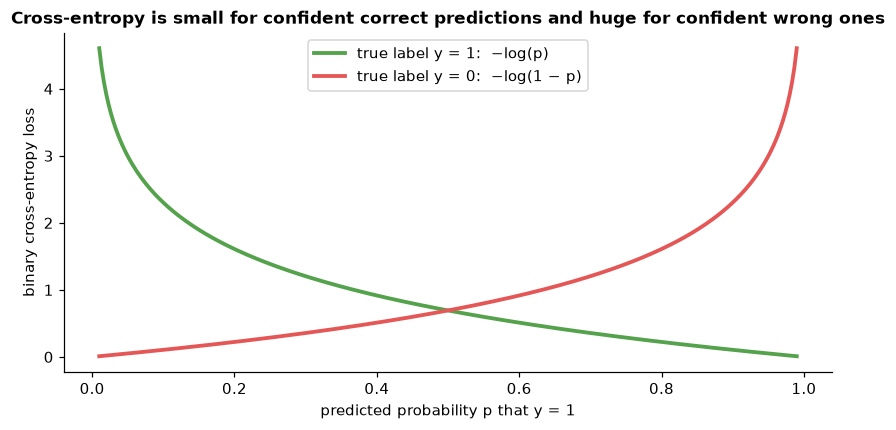

**Binary cross-entropy**

In [6]:
import numpy as np
from tensorflow import keras

y_true = np.array([1, 0, 1, 1, 0], dtype="float32")
y_prob = np.array([0.9, 0.2, 0.6, 0.95, 0.4], dtype="float32")

def binary_cross_entropy(y, p, eps=1e-7):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

print("NumPy:", round(binary_cross_entropy(y_true, y_prob), 4))
print("Keras:", round(float(keras.losses.BinaryCrossentropy()(y_true, y_prob)), 4))

NumPy: 0.2803
Keras: 0.2803


**Explanation:** Binary cross-entropy (log loss) compares predicted probabilities with 0/1 labels. It is the standard loss for a network with a sigmoid output.

**Hinge loss**

In [7]:
import numpy as np
from tensorflow import keras

y_true = np.array([1, -1, 1, 1, -1], dtype="float32")    # labels must be -1 or +1
scores = np.array([2.0, -0.5, 0.3, 1.5, 0.8], dtype="float32")

def hinge(y, s):
    return np.mean(np.maximum(0, 1 - y * s))

print("NumPy:", hinge(y_true, scores))
print("Keras:", round(float(keras.losses.Hinge()(y_true, scores)), 4))

NumPy: 0.6
Keras: 0.6


**Explanation:** Hinge loss is used by support vector machines. Labels are -1 or +1, and a prediction is only penalised if it is wrong or not confident enough (y × score below 1). Correct predictions with a margin of at least 1 have zero loss.

## 3. Multi-class classification loss functions

**Categorical cross-entropy**

In [8]:
import numpy as np
from tensorflow import keras

y_true = np.array([[0, 1, 0], [0, 0, 1]], dtype="float32")          # one-hot labels
y_prob = np.array([[0.05, 0.9, 0.05], [0.1, 0.3, 0.6]], dtype="float32")  # softmax outputs

def categorical_cross_entropy(y, p, eps=1e-7):
    p = np.clip(p, eps, 1.0)
    return -np.mean(np.sum(y * np.log(p), axis=1))

print("NumPy:", round(categorical_cross_entropy(y_true, y_prob), 4))
print("Keras:", round(float(keras.losses.CategoricalCrossentropy()(y_true, y_prob)), 4))

NumPy: 0.3081
Keras: 0.3081


**Explanation:** For more than two classes, the network outputs one probability per class (softmax), and categorical cross-entropy takes −log of the probability given to the correct class. The confident correct first prediction costs little; the less confident second one costs more.

**Kullback-Leibler (KL) divergence**

In [9]:
import numpy as np
from tensorflow import keras

p_true = np.array([[0.1, 0.6, 0.3]], dtype="float32")
q_pred = np.array([[0.2, 0.5, 0.3]], dtype="float32")

def kl_divergence(p, q, eps=1e-7):
    p, q = np.clip(p, eps, 1), np.clip(q, eps, 1)
    return np.mean(np.sum(p * np.log(p / q), axis=1))

print("NumPy:", round(kl_divergence(p_true, q_pred), 4))
print("Keras:", round(float(keras.losses.KLDivergence()(p_true, q_pred)), 4))
print("KL of identical distributions:", kl_divergence(p_true, p_true))

NumPy: 0.0401
Keras: 0.0401
KL of identical distributions: 0.0


**Explanation:** KL divergence measures how one probability distribution differs from another. It is 0 when the two are identical and grows as they differ. It is used when the target is itself a distribution, for example in variational autoencoders.

**Train a classifier with categorical cross-entropy**

In [10]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

keras.utils.set_random_seed(42)
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

y_train_1hot = keras.utils.to_categorical(y_train, 3)
y_test_1hot = keras.utils.to_categorical(y_test, 3)

model = keras.Sequential([
    keras.Input(shape=(4,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(3, activation="softmax"),
])
model.compile(optimizer=keras.optimizers.Adam(0.01), loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train_1hot, epochs=200, verbose=0)

print("Final training loss:", round(history.history["loss"][-1], 4))
print("Test accuracy:", round(model.evaluate(X_test, y_test_1hot, verbose=0)[1], 3))

Final training loss: 0.0349
Test accuracy: 0.947


**Explanation:** The iris flowers have 3 classes, so the network ends in 3 softmax neurons and is trained with categorical cross-entropy on one-hot labels. Adam with a learning rate of 0.01 is used so training converges within 200 epochs. The loss falls during training and the model classifies about 95% of the test flowers correctly.

**Compare training with different classification losses**

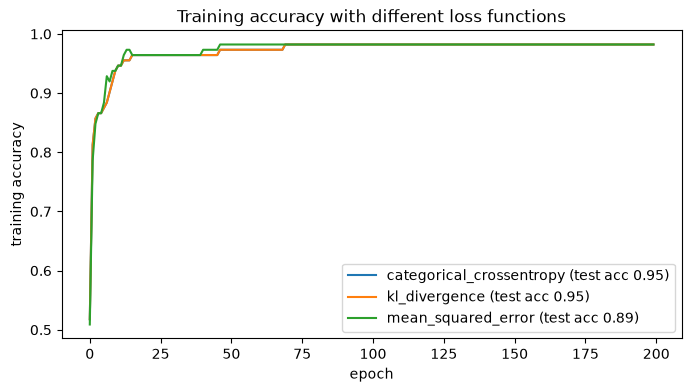

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
y_train_1hot = keras.utils.to_categorical(y_train, 3)
y_test_1hot = keras.utils.to_categorical(y_test, 3)

plt.figure(figsize=(8, 4))
for loss in ["categorical_crossentropy", "kl_divergence", "mean_squared_error"]:
    keras.utils.set_random_seed(42)
    model = keras.Sequential([keras.Input(shape=(4,)), keras.layers.Dense(16, activation="relu"),
                              keras.layers.Dense(3, activation="softmax")])
    model.compile(optimizer=keras.optimizers.Adam(0.01), loss=loss, metrics=["accuracy"])
    h = model.fit(X_train, y_train_1hot, epochs=200, verbose=0)
    acc = model.evaluate(X_test, y_test_1hot, verbose=0)[1]
    plt.plot(h.history["accuracy"], label=f"{loss} (test acc {acc:.2f})")
plt.xlabel("epoch")
plt.ylabel("training accuracy")
plt.legend()
plt.title("Training accuracy with different loss functions")
plt.show()

**Explanation:** For one-hot labels, KL divergence gives the same gradients as categorical cross-entropy, so their curves lie on top of each other. Mean squared error can also train a classifier, but here it ends with lower test accuracy (about 0.89 against 0.95). Cross-entropy is the standard choice for classification because it penalises confident wrong answers much more strongly.

## Observation

- A loss function measures the error for one prediction; the cost function averages it over the data set.
- Regression uses squared error (sensitive to outliers), absolute error (robust to outliers) or Huber loss (a mix of both).
- Binary classification uses binary cross-entropy for probabilities or hinge loss for -1/+1 margins.
- Multi-class classification uses categorical cross-entropy with a softmax output; KL divergence compares whole probability distributions.
- The NumPy implementations give the same values as the Keras built-in losses.
- Training with different losses changes what the network learns: MSE was pulled by outliers, while MAE and Huber were not.

## Conclusion

The loss function defines what "good" means for a neural network. Choosing one that matches the problem type and the data, for example a robust loss when there are outliers, is as important as choosing the network architecture.